# Day-ahead prediction

Do the models' gains over a member's own record come from earlier roll calls on the same day? In the European Parliament they mostly did ([its notebook 01](../../../../european_parliament/pipeline/vote_prediction/notebooks/01_model_comparison.ipynb)). This notebook runs the same check here.

Setup (details in [docs](../docs/README.md)):

- **Target and rows** as in [notebook 01](01_model_comparison.ipynb): a Democrat or Republican Yea or Nay against their own party's realised position on the roll call, leaving the member out, on roll calls that aren't near-unanimous. Every model knows both parties' realised positions.
- **Two settings:**
  - **one roll call ahead** (the models of notebook 01): history includes the member's votes on earlier roll calls the same day;
  - **day-ahead** (models marked "day-ahead"): history stops at the end of the member's previous day with votes, as if all of a day's predictions were made before its first roll call. Voteview records dates but not times, so "earlier the same day" means a lower roll number on the same date.
- **Time split** as in notebook 01: train 1991 to 2010, choose trees and epochs on 2011 to 2014, test on 2015 to 2024 (114th to 118th Congress).
- **Uncertainty:** a bootstrap of days and members. Notebook 01 resampled roll calls; days are the cautious choice when same-day votes depend on each other.

Predictions come from `run_model.py` and are read from `outputs/predictions.parquet`.

In [1]:
import sys
import warnings
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score, roc_auc_score

sys.path.append(str(Path.cwd().parent))
from run_model import summarise  # noqa: E402

SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#8f5bd6"]
NEUTRAL = "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#b5b4ad",
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e6e5df", "grid.linewidth": 0.8,
    "lines.linewidth": 2, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "text.color": "#0b0b0b", "xtick.color": NEUTRAL, "ytick.color": NEUTRAL,
    "legend.frameon": False,
})
MODELS = {
    "party_line": "Party line",
    "own_past_rate": "Own past rate", "logistic": "Logistic regression", "boosting": "Gradient boosting",
    "gru_seed0": "GRU, seed 0", "gru_seed1": "GRU, seed 1", "gru_seed2": "GRU, seed 2",
    "own_past_rate_day": "Own past rate, day-ahead", "logistic_day": "Logistic regression, day-ahead",
    "boosting_day": "Gradient boosting, day-ahead", "gru_day_seed0": "GRU, day-ahead, seed 0",
    "gru_day_seed1": "GRU, day-ahead, seed 1", "gru_day_seed2": "GRU, day-ahead, seed 2",
}

predictions = pd.read_parquet(Path.cwd().parent / "outputs" / "predictions.parquet")
keys = ["person", "chamber", "party"]
ordered = predictions.sort_values(keys + ["date", "rollnumber"])
new_member = ordered[keys].ne(ordered[keys].shift()).any(axis=1)
first = new_member | (ordered["date"] != ordered["date"].shift())
predictions["first_of_day"] = first.reindex(predictions.index).to_numpy()
test = predictions[predictions["split"] == "test"].reset_index(drop=True)
n_rollcalls = test[["congress", "chamber", "rollnumber"]].drop_duplicates().shape[0]
n_days = test[["chamber", "date"]].drop_duplicates().shape[0]
print(f"Test: {len(test):,} votes on {n_rollcalls:,} roll calls by {test['person'].nunique():,} members "
      f"on {n_days:,} chamber-days; defection rate {test['defected'].mean():.4f}")

Test: 2,319,540 votes on 8,027 roll calls by 883 members on 2,069 chamber-days; defection rate 0.0638


## How the data are laid out in time

How many contested roll calls a day has, how often a vote is a member's first of the day, and how strongly a defection follows a defection earlier the same day.

In [2]:
calls = test.drop_duplicates(["congress", "chamber", "rollnumber"])
per_day = calls.groupby(["chamber", "date"]).size()
display(per_day.groupby("chamber").describe()[["count", "mean", "25%", "50%", "75%", "max"]].round(1)
        .rename(columns={"count": "days", "mean": "roll calls per day, mean"}))
in_test = ordered["split"] == "test"
part = ordered[in_test]
same_day_previous = part.groupby(keys + ["date"], sort=False)["defected"].shift(1)
has_previous = same_day_previous.notna()
print(f"Votes that are a member's first of the day: {test['first_of_day'].mean():.3f} "
      f"(by chamber: {test.groupby('chamber')['first_of_day'].mean().round(3).to_dict()})")
print(f"Defection rate, first vote of the day: {test.loc[test['first_of_day'], 'defected'].mean():.4f}; "
      f"later votes: {test.loc[~test['first_of_day'], 'defected'].mean():.4f}")
print(f"Defection after a defection earlier the same day: {part.loc[has_previous & (same_day_previous == True), 'defected'].mean():.3f}; "
      f"after a loyal vote earlier the same day: {part.loc[has_previous & (same_day_previous == False), 'defected'].mean():.3f}")

# Weighted by votes, a typical vote sits on a busier day than the median day.
calls_on_day = test.groupby(["chamber", "date"])["rollnumber"].transform("nunique")
print(f"Contested roll calls on the vote's day, weighted by votes: median {calls_on_day.median():.0f}, "
      f"quartiles {calls_on_day.quantile(0.25):.0f} / {calls_on_day.quantile(0.75):.0f}")

# Whether a roll call follows one on the same bill the same day (the European Parliament's counterpart is 89%).
sys.path.append(str(Path.cwd().parents[1] / "data_loading"))
from voteview import load_rollcalls  # noqa: E402
bills = load_rollcalls()[["congress", "chamber", "rollnumber", "bill_number"]]
calls = calls.merge(bills, on=["congress", "chamber", "rollnumber"], how="left").sort_values(["chamber", "date", "rollnumber"])
previous_call = calls.groupby(["chamber", "date"])[["bill_number"]].shift(1)["bill_number"]
calls["same_bill_as_previous"] = calls["bill_number"].notna() & calls["bill_number"].eq(previous_call)
has_previous_call = calls.groupby(["chamber", "date"]).cumcount() > 0
print(f"Roll calls with an earlier contested roll call the same day: {has_previous_call.mean():.3f}; "
      f"of those, on the same bill as the previous one: {calls.loc[has_previous_call, 'same_bill_as_previous'].mean():.3f} "
      f"(no bill number on {calls['bill_number'].isna().mean():.3f} of roll calls)")
test = test.merge(calls[["congress", "chamber", "rollnumber", "same_bill_as_previous"]], on=["congress", "chamber", "rollnumber"], how="left")

# Voteview has calendar dates only, so a session running past midnight splits across two dates. Votes on a date whose
# previous voting date in the chamber is the calendar day before are where this can happen.
chamber_days = test[["chamber", "date"]].drop_duplicates().sort_values(["chamber", "date"])
chamber_days["after_previous_calendar_day"] = (chamber_days.groupby("chamber")["date"].diff() == pd.Timedelta(days=1)).to_numpy()
test = test.merge(chamber_days, on=["chamber", "date"], how="left")
print(f"Votes on a date right after another voting date in the chamber: {test['after_previous_calendar_day'].mean():.3f}")

,days,"roll calls per day, mean",25%,50%,75%,max
chamber,,,,,,
House,960.0,5.1,2.0,4.0,6.0,52.0
Senate,1109.0,2.9,1.0,2.0,4.0,34.0


Votes that are a member's first of the day: 0.218 (by chamber: {'House': 0.199, 'Senate': 0.351})
Defection rate, first vote of the day: 0.0535; later votes: 0.0667
Defection after a defection earlier the same day: 0.296; after a loyal vote earlier the same day: 0.052


Contested roll calls on the vote's day, weighted by votes: median 6, quartiles 4 / 13
Roll calls with an earlier contested roll call the same day: 0.742; of those, on the same bill as the previous one: 0.612 (no bill number on 0.024 of roll calls)


Votes on a date right after another voting date in the chamber: 0.791


- **Fewer contested roll calls a day than in the European Parliament.** In the test years a House day has a median of 4 contested roll calls, and a Senate day 2. Weighted by votes, a typical vote is on a day with 6 (quartiles 4 and 13). European Parliament sitting days have dozens of roll calls, seconds apart.
- **22% of votes are a member's first of the day** (20% in the House, 35% in the Senate), against 1.7% in the European Parliament.
- **Runs on the same bill are common here too.** Of roll calls with an earlier contested roll call that day, 61% are on the same bill as the previous one, against 89% on the same text in the European Parliament.
- **Defections cluster within a day:** after a defection earlier the same day, the member defects on 29.6% of votes; after a loyal vote, on 5.2%. That doesn't say same-day history adds anything. Members who defect often do so on many days, and their earlier days already show it. The next sections test what it adds.
- **Dates, not sessions:** Voteview has calendar dates only, so a session running past midnight puts its later votes on the next date. Day-ahead history would then include votes minutes earlier. 79% of votes are on a date right after another voting date in the chamber, so consecutive dates are the norm and this can't be isolated by date alone.

## Test results

In [3]:
subsets = {"all votes": np.ones(len(test), bool), "party-opposed": test["party_opposed"].to_numpy(),
           "parties agree": ~test["party_opposed"].to_numpy(), "first vote of the day": test["first_of_day"].to_numpy()}
tables = {}
for label, mask in subsets.items():
    part = test[mask]
    with warnings.catch_warnings():  # the party-opposed column is empty where the parties agree
        warnings.simplefilter("ignore", RuntimeWarning)
        tables[label] = pd.DataFrame({MODELS[m]: summarise(part, part[f"p_{m}"].to_numpy()) for m in MODELS}).T
    tables[label].loc[:, "defection_rate"] = part["defected"].mean()
display(tables["all votes"].drop(columns="defection_log_loss").round(4))
for label in ["party-opposed", "parties agree"]:
    print(label)
    display(tables[label][["vote_accuracy", "defection_auc", "defection_average_precision", "defection_rate"]].round(4))

# Gains over the own past rate in the same setting, on four measures: ranking (AUC, average precision) and the
# 0.5-threshold vote prediction (accuracy, share of defections caught).
measures = ["defection_auc", "defection_average_precision", "vote_accuracy", "defections_caught"]
main = tables["all votes"]
gains = pd.DataFrame({
    f"{name}, {setting}": main.loc[f"{name}{suffix}", measures] - main.loc[f"Own past rate{suffix}", measures]
    for setting, suffix in [("one ahead", ""), ("day-ahead", ", day-ahead")]
    for name in ["Logistic regression", "Gradient boosting"]}
    | {"GRU seed 0, one ahead": main.loc["GRU, seed 0", measures] - main.loc["Own past rate", measures],
       "GRU seed 0, day-ahead": main.loc["GRU, day-ahead, seed 0", measures] - main.loc["Own past rate, day-ahead", measures]}).T
print("Gain over the own past rate in the same setting:")
display(gains.round(4))

,vote_accuracy,vote_accuracy_party_opposed,defection_auc,defection_average_precision,defections_caught,flag_precision,defection_rate
Party line,0.9362,0.9528,0.5000,0.0638,0.0000,0.0000,0.0638
Own past rate,0.9380,0.9528,0.7734,0.2695,0.0627,0.6499,0.0638
Logistic regression,0.9396,0.9540,0.8305,0.3622,0.1379,0.6226,0.0638
Gradient boosting,0.9400,0.9547,0.8497,0.3794,0.1388,0.6404,0.0638
"GRU, seed 0",0.9418,0.9555,0.8542,0.4091,0.1910,0.6490,0.0638
"GRU, seed 1",0.9411,0.9552,0.8575,0.4005,0.1688,0.6470,0.0638
"GRU, seed 2",0.9414,0.9556,0.8562,0.4070,0.1643,0.6661,0.0638
"Own past rate, day-ahead",0.9380,0.9528,0.7702,0.2667,0.0624,0.6464,0.0638
"Logistic regression, day-ahead",0.9387,0.9533,0.8183,0.3298,0.1154,0.6022,0.0638
"Gradient boosting, day-ahead",0.9388,0.9539,0.8404,0.3473,0.0954,0.6414,0.0638


party-opposed


,vote_accuracy,defection_auc,defection_average_precision,defection_rate
Party line,0.9528,0.5000,0.0472,0.0472
Own past rate,0.9528,0.7346,0.1493,0.0472
Logistic regression,0.9540,0.8036,0.2830,0.0472
Gradient boosting,0.9547,0.8375,0.3205,0.0472
"GRU, seed 0",0.9555,0.8391,0.3392,0.0472
"GRU, seed 1",0.9552,0.8418,0.3369,0.0472
"GRU, seed 2",0.9556,0.8437,0.3457,0.0472
"Own past rate, day-ahead",0.9528,0.7300,0.1467,0.0472
"Logistic regression, day-ahead",0.9533,0.7885,0.2380,0.0472
"Gradient boosting, day-ahead",0.9539,0.8272,0.2837,0.0472


parties agree


,vote_accuracy,defection_auc,defection_average_precision,defection_rate
Party line,0.8688,0.5000,0.1312,0.1312
Own past rate,0.8782,0.7829,0.4144,0.1312
Logistic regression,0.8814,0.8256,0.4657,0.1312
Gradient boosting,0.8806,0.8187,0.4591,0.1312
"GRU, seed 0",0.8861,0.8366,0.5085,0.1312
"GRU, seed 1",0.8840,0.8436,0.5091,0.1312
"GRU, seed 2",0.8841,0.8340,0.4955,0.1312
"Own past rate, day-ahead",0.8780,0.7807,0.4107,0.1312
"Logistic regression, day-ahead",0.8792,0.8177,0.4464,0.1312
"Gradient boosting, day-ahead",0.8779,0.8089,0.4318,0.1312


Gain over the own past rate in the same setting:


,defection_auc,defection_average_precision,vote_accuracy,defections_caught
"Logistic regression, one ahead",0.0571,0.0927,0.0016,0.0753
"Gradient boosting, one ahead",0.0762,0.1099,0.0020,0.0761
"Logistic regression, day-ahead",0.0481,0.0631,0.0007,0.0530
"Gradient boosting, day-ahead",0.0702,0.0806,0.0009,0.0330
"GRU seed 0, one ahead",0.0808,0.1396,0.0038,0.1284
"GRU seed 0, day-ahead",0.0602,0.0688,-0.0002,-0.0179


**The test years** (2015 to 2024) have 2.3 million votes on 8,027 roll calls by 883 members, over 2,069 chamber-days. 6.4% of votes go against the party position.

- **Day-ahead, the fitted models keep most of their AUC gain.** AUC is 0.770 for the own past rate, 0.818 for logistic regression and 0.840 for boosting. The day-ahead GRU gets 0.828 to 0.834 over three seeds. One roll call ahead, these are 0.773, 0.831, 0.850 and 0.854 to 0.858. Boosting's gain over the own past rate is +0.070 day-ahead against +0.076 one roll call ahead.
- **Average precision and the vote prediction keep much less.**
  - Boosting's gain in average precision over the own past rate falls from +0.110 to +0.081. The best model's gain falls from +0.140 (GRU, one ahead) to +0.081 (boosting, day-ahead).
  - Defections caught at a 0.5 threshold: 19.1% for the GRU and 13.9% for boosting one roll call ahead, against 9.5% for day-ahead boosting and 4.5% to 11.5% for the day-ahead GRU seeds.
  - Vote accuracy: the GRU beats the party line by 0.56 points one roll call ahead (94.18% against 93.62%). The best day-ahead model, boosting, does so by 0.26 points (93.88%), and only 0.09 points above the own past rate.
  - So same-day history matters little for ranking members, but much of the gain at the top of the ranking, where a model must be confident enough to flip a vote, rests on it.
- **Both kinds of roll call** show the same AUC pattern. On party-opposed roll calls (4.7% defections), day-ahead boosting gives 0.827 against 0.838 one roll call ahead. Where the parties agree (13.1% defections), it gives 0.809 against 0.819.

## Are the steps larger than chance?

A two-way bootstrap: each draw resamples chamber-days and members together, weighting each vote by how often its day and its member were drawn. 1,000 draws, as in notebook 01. Differences in AUC and average precision, over all votes, on each kind of roll call, and on members' first votes of the day. GRU seeds 1 and 2 aren't bootstrapped.

In [4]:
class Ranked:
    """Scores sorted once, so each bootstrap draw only reweights. Per distinct score, the weighted positives and
    totals give both AUC (ties counted half) and average precision (stepping at each distinct score, as scikit-learn
    does). index maps sorted positions to rows of the whole test table."""

    def __init__(self, rows, score, y):
        order = np.argsort(score, kind="mergesort")
        self.index = rows[order]
        sorted_score = score[order]
        self.starts = np.flatnonzero(np.r_[True, sorted_score[1:] != sorted_score[:-1]])
        self.y = y[order]

    def both(self, w):
        ww = w[self.index]
        pos = np.add.reduceat(ww * self.y, self.starts)
        neg = np.add.reduceat(ww, self.starts) - pos
        below = np.cumsum(neg) - neg
        auc = (pos * (below + neg / 2)).sum() / (pos.sum() * neg.sum())
        tp, fp = np.cumsum(pos[::-1]), np.cumsum(neg[::-1])
        ap = np.sum(pos[::-1] / tp[-1] * tp / np.maximum(tp + fp, 1e-12))
        return float(auc), float(ap)


y = test["defected"].to_numpy().astype(float)
ladder = ["own_past_rate", "logistic", "boosting", "gru_seed0", "own_past_rate_day", "logistic_day", "boosting_day", "gru_day_seed0"]
ranked = {(label, m): Ranked(np.flatnonzero(mask), test.loc[mask, f"p_{m}"].to_numpy(), y[mask])
          for label, mask in subsets.items() for m in ladder}
ones = np.ones(len(test))
for m in ["boosting", "gru_day_seed0"]:
    auc, ap = ranked[("all votes", m)].both(ones)
    assert abs(auc - roc_auc_score(y, test[f"p_{m}"])) < 1e-6
    assert abs(ap - average_precision_score(y, test[f"p_{m}"])) < 1e-6

pool = ThreadPoolExecutor(8)
rng = np.random.default_rng(0)
day_keys = test["chamber"].astype(str) + " " + test["date"].astype(str)
days, day_index = np.unique(day_keys, return_inverse=True)
people, person_index = np.unique(test["person"].astype(str), return_inverse=True)
draws = []
for _ in range(1000):
    w = (np.bincount(rng.integers(0, len(days), len(days)), minlength=len(days))[day_index]
         * np.bincount(rng.integers(0, len(people), len(people)), minlength=len(people))[person_index]).astype(float)
    results = pool.map(lambda r: r.both(w), ranked.values())  # NumPy releases the GIL, so threads run in parallel
    row = {}
    for (label, m), (auc, ap) in zip(ranked, results):
        row[(label, m, "auc")], row[(label, m, "ap")] = auc, ap
    draws.append(row)
pool.shutdown()
draws = pd.DataFrame(draws)
steps = [("logistic", "own_past_rate"), ("boosting", "logistic"), ("gru_seed0", "boosting"),
         ("logistic_day", "own_past_rate_day"), ("boosting_day", "logistic_day"), ("gru_day_seed0", "boosting_day"),
         ("boosting_day", "own_past_rate_day"), ("own_past_rate", "own_past_rate_day"), ("boosting", "boosting_day"),
         ("gru_seed0", "gru_day_seed0")]
rows_out = {}
for label in subsets:
    for better, worse in steps:
        for metric in ["auc", "ap"]:
            diff = draws[(label, better, metric)] - draws[(label, worse, metric)]
            rows_out[(label, f"{MODELS[better]} over {MODELS[worse]}", metric)] = diff.quantile([0.025, 0.5, 0.975]).to_numpy()
intervals = pd.DataFrame(rows_out, index=["2.5%", "median", "97.5%"]).T
with pd.option_context("display.max_rows", 200):
    display(intervals.round(4))

2.5%  \
all votes             Logistic regression over Own past rate             auc  0.0478   
                                                                         ap   0.0794   
                      Gradient boosting over Logistic regression         auc  0.0151   
                                                                         ap   0.0063   
                      GRU, seed 0 over Gradient boosting                 auc  0.0009   
                                                                         ap   0.0191   
                      Logistic regression, day-ahead over Own past ra... auc  0.0392   
                                                                         ap   0.0525   
                      Gradient boosting, day-ahead over Logistic regr... auc  0.0171   
                                                                         ap   0.0073   
                      GRU, day-ahead, seed 0 over Gradient boosting, ... auc -0.0136   
                                                                         ap  -0.0216   
                      Gradient boosting, day-ahead over Own past rate... auc  0.0609   
                                                                         ap   0.0644   
                      Own past rate over Own past rate, day-ahead        auc  0.0023   
                                                                         ap   0.0017   
                      Gradient boosting over Gradient boosting, day-a... auc  0.0073   
                                                                         ap   0.0243   
                      GRU, seed 0 over GRU, day-ahead, seed 0            auc  0.0190   
                                                                         ap   0.0593   
party-opposed         Logistic regression over Own past rate             auc  0.0554   
                                                                         ap   0.1132   
                      Gradient boosting over Logistic regression         auc  0.0281   
                                                                         ap   0.0274   
                      GRU, seed 0 over Gradient boosting                 auc -0.0028   
                                                                         ap   0.0084   
                      Logistic regression, day-ahead over Own past ra... auc  0.0451   
                                                                         ap   0.0736   
                      Gradient boosting, day-ahead over Logistic regr... auc  0.0311   
                                                                         ap   0.0354   
                      GRU, day-ahead, seed 0 over Gradient boosting, ... auc -0.0170   
                                                                         ap  -0.0231   
                      Gradient boosting, day-ahead over Own past rate... auc  0.0849   
                                                                         ap   0.1178   
                      Own past rate over Own past rate, day-ahead        auc  0.0030   
                                                                         ap   0.0015   
                      Gradient boosting over Gradient boosting, day-a... auc  0.0079   
                                                                         ap   0.0269   
                      GRU, seed 0 over GRU, day-ahead, seed 0            auc  0.0177   
                                                                         ap   0.0508   
parties agree         Logistic regression over Own past rate             auc  0.0354   
                                                                         ap   0.0407   
                      Gradient boosting over Logistic regression         auc -0.0133   
                                                                         ap  -0.0211   
                      GRU, seed 0 over Gradient boosting                 auc  0.0100   
                                

95% intervals from 1,000 two-way draws of chamber-days and members.

**Day-ahead:**
- Boosting over the own past rate: AUC +0.070 (+0.061 to +0.079), and average precision +0.080. Logistic regression over the own past rate gives +0.048 (+0.039 to +0.057), and boosting over logistic regression +0.022 (+0.017 to +0.028).
- On party-opposed roll calls, boosting over the own past rate is +0.097 (+0.085 to +0.110). Where the parties agree it is +0.029 (+0.019 to +0.039).
- GRU seed 0 is below day-ahead boosting: −0.010 (−0.014 to −0.006). The other two seeds give 0.828 and 0.834 against 0.840 (not bootstrapped). This design gets the previous day only as three rates at each day's first vote. It is one design, so this says it doesn't beat boosting, not that a sequence model can't.

**What the same day adds:**
- Boosting gains +0.009 AUC (+0.007 to +0.011) and +0.032 average precision. The own past rate gains +0.003.
- The GRU gains +0.024 (+0.019 to +0.029). That is an upper bound for what same-day outcomes add to it. On first votes of the day, where both GRUs have the same information, seed 0's one-ahead version still leads its day-ahead version by +0.007 (+0.000 to +0.013), so part of the gap is the design.
- These are clearly above zero, but small next to day-ahead boosting's +0.070 over the own past rate.

**One roll call ahead, with days resampled instead of roll calls** (notebook 01 resampled roll calls):
- The ladder holds: logistic regression over the own past rate +0.057, and boosting over logistic regression +0.019 (+0.015 to +0.023).
- The GRU over boosting is +0.004 (+0.001 to +0.008) on all votes. On party-opposed roll calls it isn't established (−0.003 to +0.006).
- Where the parties agree, boosting is below logistic regression: −0.007 (−0.013 to −0.0004). Notebook 01's roll-call bootstrap gave nearly the same interval (−0.013 to −0.001). Both only just exclude zero.

**First votes of the day:** the GRU over boosting is −0.006 (−0.012 to −0.0001), so boosting ranks first votes slightly better.

The intervals hold the fitted models fixed, so they don't include refit variation (seed, early stopping). The three one-roll-call-ahead seeds differ by 0.003 in AUC, and the three day-ahead seeds by 0.005.

## First vote of the day or later

A member's first vote of a day is the one place where the one-roll-call-ahead models have no same-day history either.

In [5]:
day_models = ["own_past_rate", "logistic", "boosting", "gru_seed0", "own_past_rate_day", "boosting_day", "gru_day_seed0"]
day_table = test.groupby("first_of_day").apply(lambda part: pd.Series({
    "votes": len(part), "defection_rate": part["defected"].mean(),
    **{f"AUC {MODELS[m]}": roc_auc_score(part["defected"], part[f"p_{m}"]) for m in day_models},
    **{f"AP {MODELS[m]}": average_precision_score(part["defected"], part[f"p_{m}"]) for m in day_models}}),
    include_groups=False)
day_table.index = day_table.index.map({True: "first vote of the day", False: "later votes"})
display(day_table.T.round(3))

# Later votes split by whether the previous roll call that day was on the same bill, and by whether the date directly
# follows another voting date (where a session past midnight could put same-session votes on the previous date).
later = test[~test["first_of_day"]]
split_models = ["own_past_rate_day", "boosting", "boosting_day", "gru_seed0", "gru_day_seed0"]
for column, labels in [("same_bill_as_previous", {True: "previous roll call on the same bill", False: "other later votes"}),
                       ("after_previous_calendar_day", {True: "date right after another voting date", False: "other dates"})]:
    split = later.groupby(column).apply(lambda part: pd.Series({
        "votes": len(part), "defection_rate": part["defected"].mean(),
        **{f"AUC {MODELS[m]}": roc_auc_score(part["defected"], part[f"p_{m}"]) for m in split_models}}),
        include_groups=False)
    split.index = split.index.map(labels)
    split["boosting: same-day gain"] = split["AUC Gradient boosting"] - split["AUC Gradient boosting, day-ahead"]
    split["GRU: same-day gain"] = split["AUC GRU, seed 0"] - split["AUC GRU, day-ahead, seed 0"]
    print("Later votes of the day:")
    display(split.T.round(3))

first_of_day,later votes,first vote of the day
votes,1813390.000,506150.000
defection_rate,0.067,0.054
AUC Own past rate,0.771,0.787
AUC Logistic regression,0.823,0.856
AUC Gradient boosting,0.842,0.876
"AUC GRU, seed 0",0.850,0.870
"AUC Own past rate, day-ahead",0.767,0.787
"AUC Gradient boosting, day-ahead",0.831,0.875
"AUC GRU, day-ahead, seed 0",0.821,0.863
AP Own past rate,0.275,0.258


Later votes of the day:


same_bill_as_previous,other later votes,previous roll call on the same bill
votes,613859.000,1199531.000
defection_rate,0.078,0.061
"AUC Own past rate, day-ahead",0.760,0.770
AUC Gradient boosting,0.812,0.865
"AUC Gradient boosting, day-ahead",0.809,0.847
"AUC GRU, seed 0",0.806,0.880
"AUC GRU, day-ahead, seed 0",0.802,0.843
boosting: same-day gain,0.002,0.018
GRU: same-day gain,0.005,0.038


Later votes of the day:


after_previous_calendar_day,other dates,date right after another voting date
votes,314800.000,1498590.000
defection_rate,0.068,0.066
"AUC Own past rate, day-ahead",0.761,0.769
AUC Gradient boosting,0.854,0.840
"AUC Gradient boosting, day-ahead",0.846,0.828
"AUC GRU, seed 0",0.856,0.849
"AUC GRU, day-ahead, seed 0",0.838,0.819
boosting: same-day gain,0.008,0.012
GRU: same-day gain,0.017,0.031


- **First votes of the day are easier to rank than later ones,** the reverse of the European Parliament. Boosting gives AUC 0.876 on first votes against 0.842 on later ones. It ranks them almost as well day-ahead (0.875), as it should, since both settings see the same history there. Why first votes are easier isn't tested. The mix of roll calls may differ, for example procedural votes opening a day.
- **The same-day gain sits in runs on the same bill.** On later votes where the previous roll call that day was on the same bill (1.2 million votes), same-day history adds +0.018 AUC to boosting and +0.038 to the GRU. On other later votes (0.6 million) it adds +0.002 and +0.005. So the same-day gain is concentrated where roll calls come in runs on one bill, as in the European Parliament, where it is concentrated in runs on one text. The two subsets also differ in kind (boosting ranks same-bill votes better and they have fewer defections), and the flag belongs to the roll call, not to the member's own previous vote, so this locates the gain rather than explaining it.
- **Sessions past midnight: the check is inconclusive.** If they hid a same-day effect, the same-day gain would be smaller on dates right after another voting date, where the previous date can be the same session. It is larger there (+0.012 for boosting, +0.031 for the GRU) than on other dates (+0.008, +0.017). But the other 21% are mostly days after a recess, which differ in kind, so this doesn't rule it out. Vote times would settle it.

## By Congress and chamber

Single fitted models without intervals. The 112th and 113th Congresses were used to choose trees and epochs, so they flatter the models slightly.

In [6]:
over_time = ["own_past_rate", "boosting", "gru_seed0", "own_past_rate_day", "boosting_day", "gru_day_seed0"]
by_congress = predictions.groupby(["congress", "chamber"]).apply(lambda part: pd.Series({
    "votes": len(part), "defection_rate": part["defected"].mean(),
    **{MODELS[m]: roc_auc_score(part["defected"], part[f"p_{m}"]) for m in over_time}}),
    include_groups=False)
print("AUC by Congress and chamber (validation 112 and 113, then test):")
display(by_congress.round(3))

AUC by Congress and chamber (validation 112 and 113, then test):


votes  defection_rate  Own past rate  Gradient boosting  \
congress chamber                                                               
112      House    597287.0           0.096          0.742              0.816   
         Senate    38899.0           0.111          0.708              0.750   
113      House    424800.0           0.083          0.743              0.826   
         Senate    51623.0           0.076          0.775              0.848   
114      House    469959.0           0.064          0.767              0.842   
         Senate    39428.0           0.099          0.726              0.782   
115      House    395888.0           0.062          0.729              0.784   
         Senate    49481.0           0.071          0.748              0.835   
116      House    337316.0           0.057          0.764              0.843   
         Senate    61773.0           0.076          0.784              0.864   
117      House    354861.0           0.055          0.811              0.887   
         Senate    84945.0           0.075          0.793              0.877   
118      House    465477.0           0.068          0.791              0.887   
         Senate    60412.0           0.070          0.843              0.887   

                  GRU, seed 0  Own past rate, day-ahead  \
congress chamber                                          
112      House          0.836                     0.739   
         Senate         0.755                     0.707   
113      House          0.843                     0.741   
         Senate         0.852                     0.772   
114      House          0.851                     0.764   
         Senate         0.805                     0.723   
115      House          0.769                     0.727   
         Senate         0.848                     0.747   
116      House          0.847                     0.759   
         Senate         0.883                     0.781   
117      House          0.894                     0.810   
         Senate         0.896                     0.792   
118      House          0.889                     0.784   
         Senate         0.903                     0.841   

                  Gradient boosting, day-ahead  GRU, day-ahead, seed 0  
congress chamber                                                        
112      House                           0.801                   0.808  
         Senate                          0.746                   0.737  
113      House                           0.818                   0.818  
         Senate                          0.835                   0.823  
114      House                           0.832                   0.823  
         Senate                          0.761                   0.753  
115      House                           0.780                   0.758  
         Senate                          0.824                   0.813  
116      House                           0.833                   0.825  
         Senate                          0.849                   0.843  
117      House                           0.883                   0.882  
         Senate                          0.866                   0.866  
118      House                           0.872                   0.861  
         Senate                          0.875                   0.877

- **Same-day history adds little in every Congress and chamber.** Day-ahead boosting is 0.004 to 0.021 AUC below one-roll-call-ahead boosting in each.
- The 115th House is hard for every model in both settings (boosting 0.784 and 0.780), as notebook 01 found.
- AUC is generally higher in the 117th and 118th Congresses than in the 114th and 115th, but not monotonically: in the House, the own past rate, the GRU and day-ahead boosting are slightly lower in the 118th than in the 117th.
- These are single fitted models. The Senate rows have 8% to 24% as many votes as the House rows in each Congress.

## Calibration

Mean predicted probability against the observed defection rate, in ten bins of predicted probability, test years.

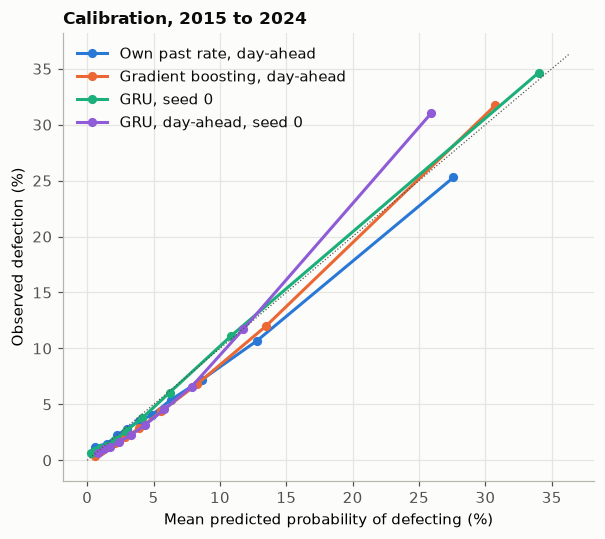

Top bin, predicted against observed:


,predicted,observed
"Own past rate, day-ahead",0.276,0.253
"Gradient boosting, day-ahead",0.308,0.317
"GRU, seed 0",0.340,0.347
"GRU, day-ahead, seed 0",0.259,0.310


Mean prediction against observed rate: {'Own past rate, day-ahead': 0.0713, 'Gradient boosting, day-ahead': 0.07, 'GRU, seed 0': 0.0635, 'GRU, day-ahead, seed 0': 0.0651} observed 0.0638


In [7]:
fig, axis = plt.subplots(figsize=(5.6, 5))
calibrated = ["own_past_rate_day", "boosting_day", "gru_seed0", "gru_day_seed0"]
for m, color in zip(calibrated, SERIES):
    p = test[f"p_{m}"]
    bins = pd.qcut(p.rank(method="first"), 10, labels=False)
    table = test.groupby(bins).agg(predicted=(f"p_{m}", "mean"), observed=("defected", "mean"))
    axis.plot(table["predicted"] * 100, table["observed"] * 100, marker="o", markersize=5, color=color, label=MODELS[m])
limit = max(axis.get_xlim()[1], axis.get_ylim()[1])
axis.plot([0, limit], [0, limit], color=NEUTRAL, linewidth=0.8, linestyle=":")
axis.set_xlabel("Mean predicted probability of defecting (%)")
axis.set_ylabel("Observed defection (%)")
axis.set_title("Calibration, 2015 to 2024")
axis.legend(loc="upper left")
fig.tight_layout()
plt.show()
bin_tables = {}
for m in calibrated:
    bins = pd.qcut(test[f"p_{m}"].rank(method="first"), 10, labels=False)
    bin_tables[MODELS[m]] = test.groupby(bins).agg(predicted=(f"p_{m}", "mean"), observed=("defected", "mean")).iloc[-1]
print("Top bin, predicted against observed:")
display(pd.DataFrame(bin_tables).T.round(3))
print("Mean prediction against observed rate:",
      {MODELS[m]: round(float(test[f"p_{m}"].mean()), 4) for m in calibrated},
      "observed", round(float(test["defected"].mean()), 4))

- One-roll-call-ahead GRU seed 0 and day-ahead boosting lie close to the diagonal, including the top bin (34.0% predicted against 34.7% observed, and 30.8% against 31.7%). Day-ahead boosting is slightly too high overall (mean 0.070 against 0.064 observed). As in notebook 01, defection was more common in training than in the test years.
- The day-ahead own past rate is too high in its top bin (27.6% predicted, 25.3% observed).
- The day-ahead GRU (seed 0) is too low in its top bin (25.9% predicted, 31.0% observed), so it is under-confident on the members most likely to defect. This fits its low share of defections caught at a 0.5 threshold.

## Compared with the European Parliament

What the same day adds, in each entity. European Parliament figures are from [its decisions](../../../../european_parliament/pipeline/vote_prediction/docs/README.md) (10th term). Targets, base rates and periods differ, so compare the gaps, not the levels.

In [8]:
names = ["Own past rate", "Logistic regression", "Gradient boosting", "GRU, seed 0"]
day_names = ["Own past rate, day-ahead", "Logistic regression, day-ahead", "Gradient boosting, day-ahead", "GRU, day-ahead, seed 0"]
compare = pd.DataFrame({
    "USA one ahead": main.loc[names, "defection_auc"].to_numpy(),
    "USA day-ahead": main.loc[day_names, "defection_auc"].to_numpy(),
    "EP one ahead": [0.726, 0.799, 0.802, 0.839],
    "EP day-ahead": [0.718, 0.734, 0.730, 0.698],
}, index=["Own past rate", "Logistic regression", "Gradient boosting", "GRU"])
compare["USA gap"] = compare["USA one ahead"] - compare["USA day-ahead"]
compare["EP gap"] = compare["EP one ahead"] - compare["EP day-ahead"]
display(compare.round(3))
print("Both GRU rows are seed 0; the European Parliament's three one-ahead seeds give 0.834 to 0.839.")

,USA one ahead,USA day-ahead,EP one ahead,EP day-ahead,USA gap,EP gap
Own past rate,0.773,0.770,0.726,0.718,0.003,0.008
Logistic regression,0.831,0.818,0.799,0.734,0.012,0.065
Gradient boosting,0.850,0.840,0.802,0.730,0.009,0.072
GRU,0.854,0.830,0.839,0.698,0.024,0.141


Both GRU rows are seed 0; the European Parliament's three one-ahead seeds give 0.834 to 0.839.


- **Same-day history matters much less in the USA than in the European Parliament.**
  - For fitted models, day-ahead costs 0.009 to 0.024 AUC here and 0.065 to 0.14 there. The own past rate loses 0.003 here and 0.008 there.
  - Day-ahead logistic regression and boosting still clearly beat the own past rate here (+0.048 and +0.070). There they add only +0.011 to +0.015, and only where the group went against most groups.
- **In both, the same-day gain is concentrated in runs of roll calls on the same bill or text** (in the European Parliament, same-text runs weren't separated from persistence within a sitting in general). What differs is how much else predicts defection.
  - In the USA, the member's record on earlier days plus the roll call's features (vote type, party-opposed, own party Yea or Nay) already rank well.
  - In the European Parliament they don't, and the previous roll call, seconds earlier on the same text, carries most of the signal.
  - Same-text runs are also more common there (89% against 61%), and first votes of the day much rarer (1.7% against 22%).
  - This is a reading of the two notebooks, not a tested explanation.
- **Average precision and accuracy depend more on same-day history than AUC** in the USA too, so "the USA results don't rest on same-day history" holds for ranking, not for flagging defections.
- Targets, base rates and periods differ between the entities, so only the gaps are compared, not the levels.

## Summary

- **Given both parties' realised positions, the fitted models' AUC gain over a member's own record mostly holds day-ahead.** On 2015 to 2024 test votes, with history only up to the previous day, boosting ranks defections at AUC 0.840 against 0.770 for the own past rate (+0.070, interval +0.061 to +0.079), against +0.076 one roll call ahead. It holds on party-opposed roll calls and where the parties agree.
- **The vote prediction keeps less.** Day-ahead boosting beats the party line by 0.26 points on accuracy (the GRU one roll call ahead by 0.56), catches 9.5% of defections (13.9% for boosting and 19.1% for the GRU one roll call ahead), and gains +0.081 in average precision over the own past rate (+0.110 for boosting, +0.140 for the GRU one roll call ahead).
- **Same-day history adds +0.009 AUC to boosting and up to +0.024 to the GRU,** mostly in runs of roll calls on the same bill. In the European Parliament it adds +0.072 and +0.14 and accounts for most of the models' gain.
- **The day-ahead GRU** (0.828 to 0.834, three seeds) is below day-ahead boosting (0.840). In this design, the GRU's small one-roll-call-ahead edge over boosting (+0.004) depends on same-day outcomes.
- **Limits:**
  - all models are conditional on the realised party positions;
  - Voteview has dates but no times, so roll numbers order votes within a day, and a session past midnight spans two dates;
  - the day-ahead GRU is one design, and its step count still includes earlier kept votes the same day;
  - intervals don't include refit variation;
  - these are associations in a selected sample of roll calls.